In [41]:
# Import Pandas for data manipulation and analysis.
# Import NumPy for numerical operations.
# Import Matplotlib for creating and customizing visualizations.
# Import Seaborn for statistical data visualization.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
# Load the healthcare insurance dataset from the CSV file.
df = pd.read_csv('/content/insurance.csv')

In [43]:
# Display the first five rows to understand the structure and contents of the dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [44]:
# Check the number of rows and columns in the dataset.
df.shape

(1338, 7)

In [45]:
# Display column names, data types, and non-null counts.
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [46]:
# Display information about the DataFrame, including column names, data types, non-null values, and memory usage.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [47]:
# Generate descriptive statistics for numerical columns.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [48]:
# Check the number of missing values in each column.
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [49]:
# Identify duplicate records in the dataset.
df.duplicated().sum()

np.int64(1)

In [50]:
# Display duplicate records to inspect them before removal.
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [51]:
# Remove duplicate records to avoid repeated observations in the analysis.
df = df.drop_duplicates()

In [67]:
# Verify that all duplicate records have been removed.
df.shape

(1337, 8)

In [68]:
# Identify the unique categories present in the gender, smoking status, and region columns.
print("Gender categories:")
print(df['sex'].unique())

print("\nSmoker categories:")
print(df['smoker'].unique())

print("\nRegion categories:")
print(df['region'].unique())

Gender categories:
['female' 'male']

Smoker categories:
['yes' 'no']

Region categories:
['southwest' 'southeast' 'northwest' 'northeast']


In [69]:
# Count the number of customers in each gender, smoking status & geographical region category.
print(df['sex'].value_counts())
print(df['smoker'].value_counts())
print(df['region'].value_counts())

sex
male      675
female    662
Name: count, dtype: int64
smoker
no     1063
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


In [70]:
# Check the number of zero values in numerical columns.
(df[['age', 'bmi', 'children', 'charges']] == 0).sum()

,0
age,0
bmi,0
children,573
charges,0


In [71]:
# Check for negative values in numerical columns to identify potentially invalid records.
(df[['age' , 'bmi', 'children', 'charges']] < 0).sum()

,0
age,0
bmi,0
children,0
charges,0


In [74]:
# Calculate Q1 and Q3
Q1_bmi = df['bmi'].quantile(0.25)
Q3_bmi = df['bmi'].quantile(0.75)

# Calculate IQR
IQR_bmi = Q3_bmi - Q1_bmi

# Calculate lower and upper bounds for identifying potential BMI outliers.
lower_bmi = Q1_bmi - 1.5 * IQR_bmi
upper_bmi = Q3_bmi + 1.5 * IQR_bmi

print("BMI Q1:", Q1_bmi)
print("BMI Q3:", Q3_bmi)
print("BMI IQR:", IQR_bmi)
print("Lower Bound:", lower_bmi)
print("Upper Bound:", upper_bmi)

BMI Q1: 26.29
BMI Q3: 34.7
BMI IQR: 8.410000000000004
Lower Bound: 13.674999999999994
Upper Bound: 47.31500000000001


In [76]:
# Identify customers whose BMI values fall below the lower boundary or above the upper boundary.
bmi_outliers = df[
    (df['bmi'] < lower_bmi) |
    (df['bmi'] > upper_bmi)
]

bmi_outliers


,age,sex,bmi,children,smoker,region,charges,age_group
116,58,male,49.06,0,no,southeast,11381.32540,Older Adults
286,46,female,48.07,2,no,northeast,9432.92530,Middle-aged
401,47,male,47.52,1,no,southeast,8083.91980,Middle-aged
543,54,female,47.41,0,yes,southeast,63770.42801,Older Adults
847,23,male,50.38,1,no,southeast,2438.05520,Young Adults
860,37,female,47.60,2,yes,southwest,46113.51100,Middle-aged
1047,22,male,52.58,1,yes,southeast,44501.39820,Young Adults
1088,52,male,47.74,1,no,southeast,9748.91060,Older Adults
1317,18,male,53.13,0,no,southeast,1163.46270,Young Adults


In [77]:
# Display the number of potential BMI outliers.
print("Number of BMI outliers:", len(bmi_outliers))

Number of BMI outliers: 9


In [78]:
# Calculate Q1 and Q3
Q1_charges = df['charges'].quantile(0.25)
Q3_charges = df['charges'].quantile(0.75)

# Calculate IQR
IQR_charges = Q3_charges - Q1_charges

# Calculate lower and upper bounds for identifying potential insurance-charge outliers.
lower_charges = Q1_charges - 1.5 * IQR_charges
upper_charges = Q3_charges + 1.5 * IQR_charges

print("Charges Q1:", Q1_charges)
print("Charges Q3:", Q3_charges)
print("Charges IQR:", IQR_charges)
print("Lower Bound:", lower_charges)
print("Upper Bound:", upper_charges)

Charges Q1: 4746.344
Charges Q3: 16657.71745
Charges IQR: 11911.37345
Lower Bound: -13120.716174999998
Upper Bound: 34524.777625


In [79]:
# Identify customers whose insurance charges fall below the lower boundary or above the upper boundary.
charges_outliers = df[
    (df['charges'] < lower_charges) |
    (df['charges'] > upper_charges)
]

charges_outliers

,age,sex,bmi,children,smoker,region,charges,age_group
14,27,male,42.130,0,yes,southeast,39611.75770,Adults
19,30,male,35.300,0,yes,southwest,36837.46700,Adults
23,34,female,31.920,1,yes,northeast,37701.87680,Adults
29,31,male,36.300,2,yes,southwest,38711.00000,Adults
30,22,male,35.600,0,yes,southwest,35585.57600,Young Adults
...,...,...,...,...,...,...,...,...
1300,45,male,30.360,0,yes,southeast,62592.87309,Middle-aged
1301,62,male,30.875,3,yes,northwest,46718.16325,Older Adults
1303,43,male,27.800,0,yes,southwest,37829.72420,Middle-aged
1313,19,female,34.700,2,yes,southwest,36397.57600,Young Adults


In [80]:
# Display the number of potential insurance-charge outliers.
print("Number of charges outliers:", len(charges_outliers))

Number of charges outliers: 139


In [81]:
# Compare the total number of customers with the number of potential BMI and insurance-charge outliers.
print("Total customers:", len(df))
print("BMI outliers:", len(bmi_outliers))
print("Charges outliers:", len(charges_outliers))

Total customers: 1337
BMI outliers: 9
Charges outliers: 139


In [82]:
# Calculate the percentage of customers flagged as potential BMI outliers.
# Calculate the percentage of customers flagged as potential insurance-charge outliers.
bmi_outlier_percentage = (len(bmi_outliers) / len(df)) * 100

charges_outlier_percentage = (len(charges_outliers) / len(df)) * 100

print("BMI outlier percentage:", bmi_outlier_percentage)
print("Charges outlier percentage:", charges_outlier_percentage)

BMI outlier percentage: 0.6731488406881078
Charges outlier percentage: 10.396409872849663


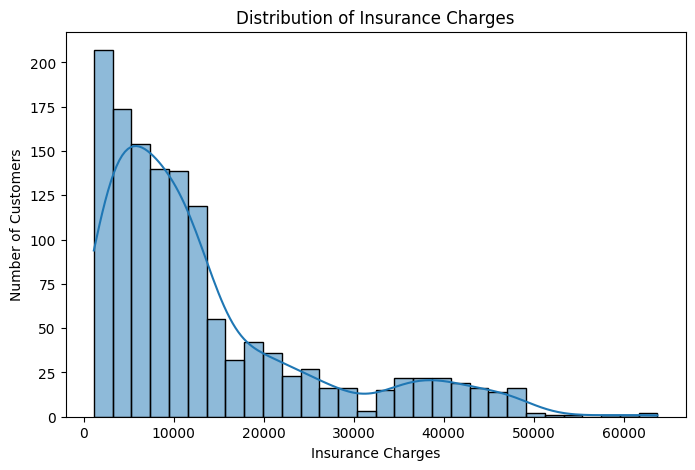

In [84]:
# Create a histogram to examine the distribution of insurance charges.
# Divide insurance charges into 30 intervals using bins=30.
# Add a smooth distribution curve using kde=True.
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='charges', bins=30, kde=True)

plt.title('Distribution of Insurance Charges')
plt.xlabel('Insurance Charges')
plt.ylabel('Number of Customers')

plt.show ()


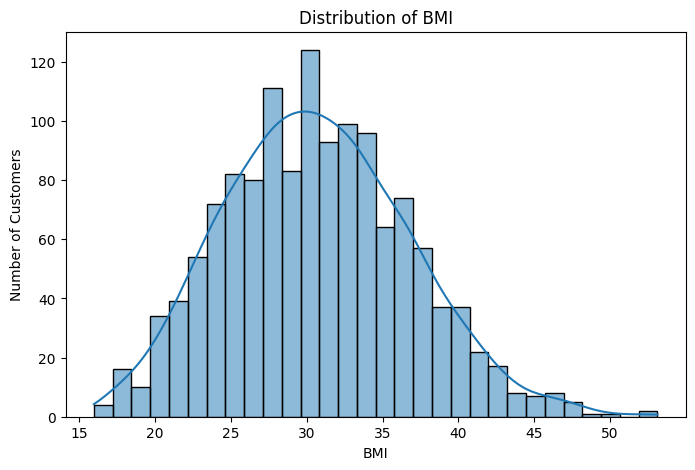

In [85]:
# Create a histogram to examine the distribution of customer BMI values.
# Divide BMI values into 30 intervals using bins=30.
# Add a smooth distribution curve using kde=True.

plt.figure(figsize = (8, 5))
sns.histplot(data = df, x = 'bmi', bins = 30, kde = True)

plt.title('Distribution of BMI')
plt.xlabel('BMI')
plt.ylabel('Number of Customers')

plt.show()

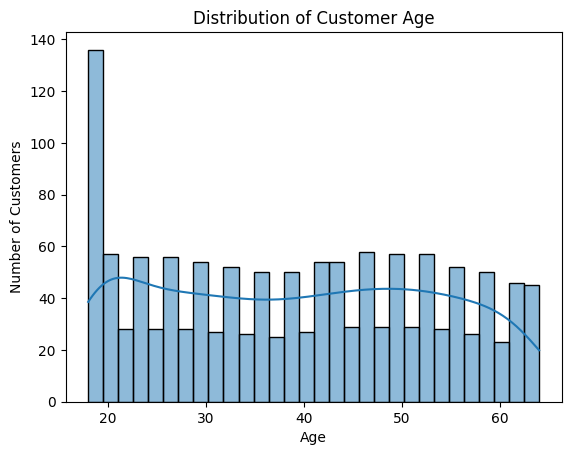

In [86]:
# Create a histogram to examine the distribution of customer ages.
# Divide age values into 30 intervals using bins=30.
# Add a smooth distribution curve using kde=True.plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

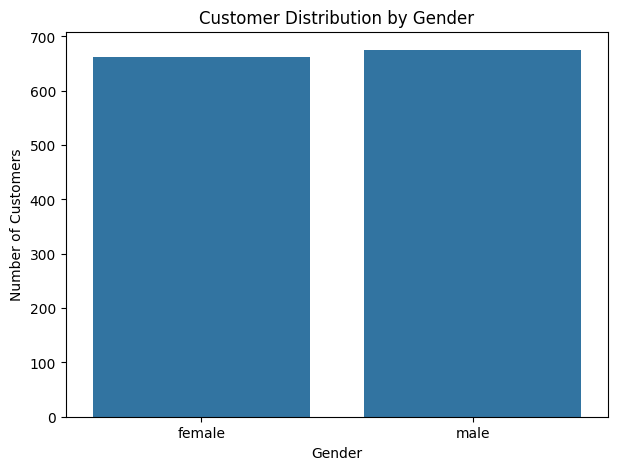

In [87]:
# Create a countplot to visualize the number of male and female customers.
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='sex')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

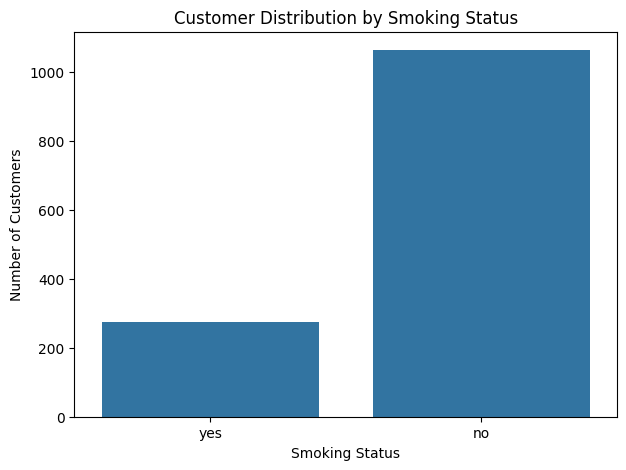

In [88]:
# Create a countplot to visualize the number of smokers and non-smokers.
plt.figure(figsize =(7,5))

sns.countplot(data = df, x ='smoker')

plt.title('Customer Distribution by Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Number of Customers')

plt.show()

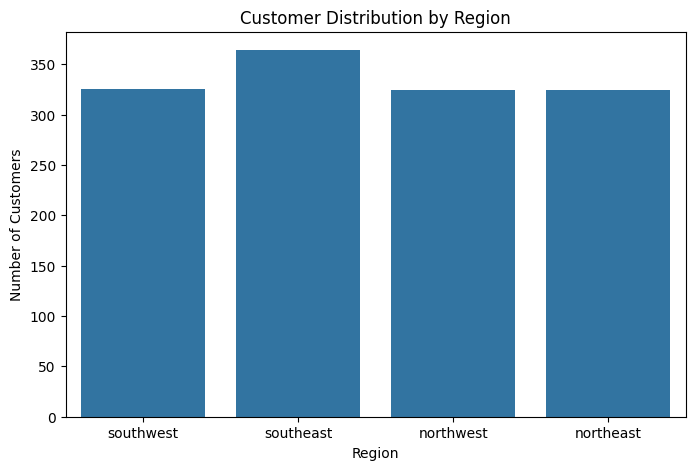

In [89]:
# Create a countplot to visualize the number of customers across geographical regions.
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='region')

plt.title('Customer Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Number of Customers')

plt.show()

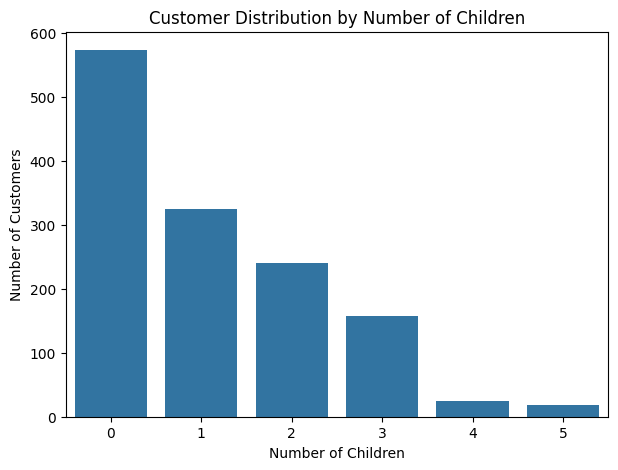

In [60]:
# Create a countplot to visualize the number of customers according to their number of children.
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='children')

plt.title('Customer Distribution by Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Number of Customers')

plt.show()

In [61]:
# Create age groups to categorize customers based on their age.
# pd.cut() divides numerical age values into specified intervals.
# bins define the boundaries of each age group.
# labels assign readable names to the age groups.

df['age_group'] = pd.cut(
    df['age'],
    bins=[17, 25, 35, 50, 64],
    labels=['Young Adults', 'Adults', 'Middle-aged', 'Older Adults']
)

In [90]:
# Create an independent copy of the DataFrame
# This helps avoid SettingWithCopyWarning when modifying the dataset.

df = df.copy()

# Create customer age groups using the age column.
# pd.cut() divides numerical ages into specified intervals.

df.loc[:, 'age_group'] = pd.cut(
    df['age'],
    bins=[17, 25, 35, 50, 64],
    labels=['Young Adults', 'Adults', 'Middle-aged', 'Older Adults']
)

In [63]:
# Display the original age column alongside the newly created age_group column.
# This helps us verify that customers have been assigned to the correct age categories.

df[['age', 'age_group']].head(10)

,age,age_group
0,19,Young Adults
1,18,Young Adults
2,28,Adults
3,33,Adults
4,32,Adults
5,31,Adults
6,46,Middle-aged
7,37,Middle-aged
8,37,Middle-aged
9,60,Older Adults


In [64]:
# Count the number of customers in each age group.
# value_counts() counts how many times each age category appears.
# sort_index() displays the categories in their original age-group order.

age_group_counts = df['age_group'].value_counts().sort_index()

print(age_group_counts)

age_group
Young Adults    305
Adults          268
Middle-aged     408
Older Adults    356
Name: count, dtype: int64


In [65]:
# Select numerical columns for correlation analysis.
# corr() calculates the correlation between each pair of numerical variables.

correlation_matrix = df[
    ['age', 'bmi', 'children', 'charges']
].corr()

# Display the correlation results.
print(correlation_matrix)


               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


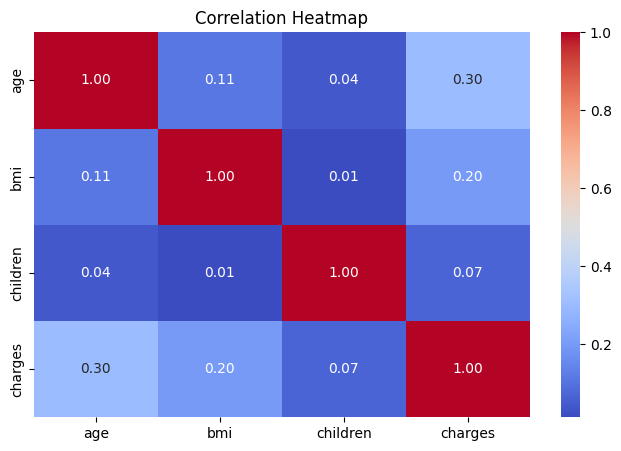

In [66]:
# Create a figure for the correlation heatmap.
plt.figure(figsize=(8, 5))

# Visualize the correlation matrix using colours and numerical values.
# annot=True displays the correlation values inside each cell.
# cmap='coolwarm' uses different colours for positive and negative correlations.
# fmt='.2f' displays values up to two decimal places.

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

# Add a title to the heatmap.
plt.title('Correlation Heatmap')

# Display the completed heatmap.
plt.show()

In [91]:
# Export the cleaned dataset, including the newly created age_group column,
# into a CSV file for importing into PostgreSQL.
df.to_csv('healthcare_insurance_cleaned.csv', index=False)

# Display a confirmation message after exporting the dataset.
print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
